In [34]:
import ast
import pygad
import math
import matplotlib.pyplot as plt
import random
import time

### <b>Data</b>

<details>
<summary><b>Transcription of the conversation with AI about datasets generation</b></summary>


#### UPORABNIK

Na podlagi priložene "original.zip" generiraj naslednje podatke:
Easy in Hard, ki imata podobno strukturo kot original, ampak lažje oz težje pogoje.
Medium, Large in Extreme, ki imajo podobne omejitve, vendar različne velikosti.
Na koncu podaj tabelo, ki prikazuje podatke in Lectures, Total hours, Classrooms, Teachers, v obliki html.


#### ASISTENT


Na podlagi strukture datoteke original.zip sem pripravil pet novih podatkovnih zbirk z naslednjimi lastnostmi.

1. Generirane podatkovne zbirke
Zbirka	Opis	Omejitve
Easy	Enaka struktura kot Original	Manjše število omejitev, večja fleksibilnost pri razporejanju
Medium	Večja različica Original	Podobne omejitve, več predavanj in virov
Hard	Enaka struktura kot Original	Strožje omejitve, manj možnosti za razporejanje
Large	Obsežnejša različica Original	Več predavanj, učilnic in profesorjev
Extreme	Največja različica Original	Zelo stroge omejitve in visoka kompleksnost razporejanja

2. Tabela rezultatov

<table>
    <thead>
        <tr>
            <th>Dataset</th>
            <th>Lectures</th>
            <th>Total hours</th>
            <th>Classrooms</th>
            <th>Teachers</th>
        </tr>
    </thead>
    <tbody>
        <tr><td>Easy</td><td>12</td><td>27</td><td>4</td><td>6</td></tr>
        <tr><td>Original</td><td>10</td><td>22</td><td>4</td><td>4</td></tr>
        <tr><td>Hard</td><td>12</td><td>31</td><td>4</td><td>4</td></tr>
        <tr><td>Medium</td><td>20</td><td>44</td><td>7</td><td>9</td></tr>
        <tr><td>Large</td><td>28</td><td>75</td><td>10</td><td>14</td></tr>
        <tr><td>Extreme</td><td>70</td><td>204</td><td>22</td><td>30</td></tr>
    </tbody>
</table>

Končni rezultat: šest zbirk (Original, Easy, Medium, Hard, Large in Extreme), primerljivih po strukturi in primernih za testiranje algoritmov za razporejanje predavanj.
</details>

<table>
    <thead>
        <tr>
            <th>Dataset</th>
            <th>Lectures</th>
            <th>Total hours</th>
            <th>Classrooms</th>
            <th>Teachers</th>
        </tr>
    </thead>
    <tbody>
        <tr><td>Easy</td><td>12</td><td>27</td><td>4</td><td>6</td></tr>
        <tr><td>Original</td><td>10</td><td>22</td><td>4</td><td>4</td></tr>
        <tr><td>Hard</td><td>12</td><td>31</td><td>4</td><td>4</td></tr>
        <tr><td>Medium</td><td>20</td><td>44</td><td>7</td><td>9</td></tr>
        <tr><td>Large</td><td>28</td><td>75</td><td>10</td><td>14</td></tr>
        <tr><td>Extreme</td><td>70</td><td>204</td><td>22</td><td>30</td></tr>
    </tbody>
</table>

<pre style="background-color: transparent; border: none; padding: 0;">
                Lecture 1   Lecture 2   Lecture 3
Chromosome:     [ 4 | 1 ]   [ 2 | 0 ]   [ 7 | 2 ]

Genes:      [Room x Start_time Index | Teacher Index]
</pre>

In [59]:
def load_data(ASSETS_PATH):

    def parse_classes(filename):
        classes = []
        with open(filename, 'r', encoding='utf-8') as f:
            for line in f:
                if not line.strip():
                    continue
                parts = line.strip().split()
                subject = parts[0]
                durations = ast.literal_eval(" ".join(parts[1:]))
                for d in durations:
                    classes.append({'subject': subject, 'duration': d})
        return classes


    def parse_classrooms(filename):
        classrooms = {}
        with open(filename, 'r', encoding='utf-8') as f:
            for line in f:
                if not line.strip():
                    continue
                parts = line.strip().split()
                name = parts[0]
                times = ast.literal_eval(" ".join(parts[1:]))
                classrooms[name] = {'start': times[0], 'end': times[1]}
        return classrooms


    def parse_teachers(filename):
        teachers = {}
        with open(filename, 'r', encoding='utf-8') as f:
            for line in f:
                if not line.strip():
                    continue
                parts = line.strip().split()
                name = parts[0]
                # Združi ostanek vrstice, odstrani oklepaje in razdeli po vejici
                raw_str = " ".join(parts[1:]).strip('[]')
                subjects = [s.strip() for s in raw_str.split(',') if s.strip()]
                teachers[name] = subjects
        return teachers

    def parse_preferences(filename):
        preferences = {}
        with open(filename, 'r', encoding='utf-8') as f:
            for line in f:
                if not line.strip():
                    continue
                parts = line.strip().split(" {")
                name = parts[0]
                pref = "{" + parts[1].replace("“", "\"").replace("”", "\"")
                preferences[name] = ast.literal_eval(pref)
        return preferences


    classes = parse_classes(ASSETS_PATH + 'Classes.txt')
    classrooms = parse_classrooms(ASSETS_PATH + 'Classrooms.txt')
    teachers = parse_teachers(ASSETS_PATH + 'Teachers.txt')
    preferences = parse_preferences(ASSETS_PATH + 'Preferences.txt')
    return classes, classrooms, teachers, preferences

### <b>TASK 1</b>

<details>
<summary><b>Transcription of the conversation with AI about Task 1</b></summary>

My Long Content
Transkripcija pogovora z AI (Claude) – Seminarska naloga 1, Task 1
Datum: 27. 10. 2026
==================================================================

[UPORABNIK]
preberi navodila v pdf in si oglej txt datoteke. rešujeva task 1. vendar ti mi nikakor ne podaš rešitve, ampak mi pomagaš razmišljati in me usmerjaš. preberi 1. nalogo in ko boš greva z idejami

[AI]
(prebere IS_Seminar_1_2026-1.pdf ter Classes.txt, Classrooms.txt, Teachers.txt, Preferences.txt)

Prebral sem navodila in vse štiri txt datoteke. Za Task 1 je cilj: GA (PyGAD) sestavi enodnevni urnik, kjer ima vsako predavanje dodeljeno učilnico, začetni čas in učitelja, pri tem pa veljajo trdi pogoji. Učilnica mora biti v tistem času na voljo, v isti učilnici se predavanja ne prekrivajo, učitelj ne uči dveh hkrati in vsako predavanje je v urniku. Zraven rabiš še fitness funkcijo in izpis urnika. Optimum ni zahtevan, GA mora samo delovati.

Dve stvari sem opazil, preden začneva:
- Pri podatkih se splača en hiter izračun. Koliko je vseh predavanj, koliko ur skupaj zahtevajo in koliko ur ponujajo vse učilnice skupaj? Poglej, kako tesno je to. P2 je odprta od 8h, ostale šele od 10h.
- Navodila zahtevajo, da oddaš log pogovora z AI. Ta pogovor bo torej del oddaje.

Prvo vprašanje je reprezentacija, ker od nje zavisi vse ostalo.

PyGAD dela z enim kromosomom, ki je ploščat vektor števil. Razmisli o tem:

1. Katere odločitve so za posamezno predavanje sploh odprte? Kaj je fiksno že iz vhoda in kaj mora GA izbrati?
2. Kako bi te odločitve zakodiral v števila? Kakšna je potem dolžina kromosoma in kaj pomeni posamezen gen?
3. Kakšna je zaloga vrednosti vsakega gena? PyGAD ima parameter gene_space, s katerim lahko vsakemu genu posebej omejiš dovoljene vrednosti. Kaj bi ti to prihranilo pri fitness funkciji?

Ko boš imel predlog, ga kar napiši, tudi če je grob. Potem ga skupaj preizkusiva: kateri pogoji iz navodil so z reprezentacijo zagotovljeni že po konstrukciji in katere mora kaznovati fitness. Če se mi bo zdelo, da kje zaideš, ti bom ugovarjal.

------------------------------------------------------------------

[UPORABNIK]
kromosom (array) bo imel toliko elementov kot je vsota razpoložljivih ur po vseh predavalnicah. šlo bo po vrsti predavalnice kot so zapisane v txt. na vsakem mestu bo bodisi prazen string bodisi string sestavljen iz imena predmeta in izvajalca.

[AI]
Predlog ima eno pravo prednost, vidim pa tudi resen problem. Ugovarjam ti s konkretnim primerom.

Kar je dobro: dva trda pogoja dobiš zastonj, že po konstrukciji. Predavanje je lahko samo v uri, ko je učilnica odprta, in v eni učilnici je v eni uri največ eno predavanje. Fitness ju sploh ne rabi preverjati. Ta ideja je vredna, da jo obdržiš v glavi.

Problem: predavanje tu nima identitete. Imaš samo posamezne ure z oznako. Poskusi dekodirati tale kos kromosoma za P2 (8h–16h):

    [Prog-Anna, Prog-Anna, Prog-Anna, Prog-Anna, Prog-Anna, "", "", ""]

Je to 2+3 (veljavno), 3+2 ali 2+2+1? Kako iz tega ugotoviš, ali je vsako predavanje iz Classes.txt (Programming [2, 3, 2, 2]) prisotno natanko enkrat in v pravi dolžini? Kaj pa, če Prog-Anna stoji v 8h, Prog-Brian v 9h in spet Prog-Anna v 10h?

Preden se odločiš, razmisli še o treh stvareh:

1. Kaj naredita mutacija in crossover z blokom ur? Recimo, da imaš lepo 3-urno predavanje in mutacija spremeni srednjo uro. Kako pogosto bosta naključna operatorja ustvarila nekaj, kar sploh ni sestavljeno iz veljavnih blokov?
2. Velikost prostora. Koliko vrednosti lahko zavzame vsak gen in koliko je genov? Primerjaj to s tem, koliko odločitev dejansko moraš sprejeti, saj je predavanj samo 10.
3. Praktična malenkost: PyGAD geni so števila, ne stringi. To je rešljivo z indeksi v seznam možnosti, vendar to upoštevaj.

Moje vprašanje zate: kaj, če razmerje obrneš? Zdaj je gen ura v učilnici in vrednost je kaj tam poteka. Kaj se zgodi, če je izhodišče predavanje in geni opisujejo, kje, kdaj in s kom poteka? Kateri pogoji postanejo potem zastonj in katere izgubiš, ki jih tvoj predlog zdaj daje po konstrukciji?

Če misliš, da se problem z identiteto da rešiti znotraj tvoje reprezentacije, mi povej kako. Potem ga preizkusiva.

------------------------------------------------------------------

[UPORABNIK]
če je fiksno predavanje imamo nato zastonj definirano, da so v pravi obliki in pravi frekvenci, morava pa kodirati kdaj se izvaja, kje in kdo.

[AI]
Točno. Identiteta, dolžina in število predavanj so zdaj fiksni in zagotovljeni. Odprta so samo še tri vprašanja na predavanje: kdaj, kje in kdo.

Naslednji korak je, kako to spraviti v PyGAD-ov vektor števil. Skozi grem po vrsti.

1. Kdo (učitelj). Vsak gen ima lahko v gene_space svoj seznam dovoljenih vrednosti. Kaj to pomeni za pogoj "učitelj mora znati predmet"? Ga mora fitness sploh še preverjati?

2. Kje in kdaj. Tu je past. Recimo, da imaš ločena gena za učilnico in začetno uro. Kaj se zgodi s 3-urnim predavanjem, ki dobi P1 in začetek ob 8h? Kaj pa ob 14h? Dovoljene začetne ure so torej odvisne od tega, katera je učilnica, ki pa je v drugem genu. gene_space ne zna izraziti odvisnosti med dvema genoma.

Imaš dve možnosti:
- Ta pogoj prepustiš fitness funkciji (kazen).
- Najdeš kodiranje, kjer te odvisnosti ni. Namig: ali morata "kje" in "kdaj" res biti dva gena?

Premisli, kaj ima katera možnost za posledico pri mutaciji in crossoverju, ne samo pri fitnessu.

3. Kaj ostane za fitness? Ko se odločiš pri 1 in 2, naštej trde pogoje iz navodil, ki niso zagotovljeni po konstrukciji. Te bo morala kaznovati fitness funkcija. Po mojem bi moral priti do dveh ali treh. Pri vsakem se vprašaj, kako ga boš meril: samo da/ne ali kot število kršitev (npr. število prekrivajočih se ur)? Za GA to ni vseeno. Zakaj?

Povej, za kaj se odločiš pri točki 2. Potem greva na fitness.

------------------------------------------------------------------

[UPORABNIK]
kdo je preprosto rešeno, ker omejiva na fiksne vrednosti, kjer vsakemu profesorju dodeliva številko, za določen del gena so dovoljena le določena števila. kje in kdaj ne rabita biti dva različna gena lahko sta združena, saj učilnici priredimo števila, začetnemu času število in nato lahko izračunamo unikatni int kot praštevilo1 na številko učilnice krat praštevilo2 na številko začetka predavanja. konec avtomatsko vemo prek tega za katero predavanje gre.

[AI]
"Kdo" je rešen pravilno. Pogoj "učitelj zna predmet" je zdaj zagotovljen po konstrukciji.

Pri "kje + kdaj" je združitev v en gen prava odločitev. Kodiranje s praštevili pa je po mojem nepotreben ovinek, in tu ti bom ugovarjal.

Kaj praštevila naredijo: po osnovnem izreku aritmetike je 2^učilnica · 3^začetek res injektivno, torej deluje. Ampak zakaj sva sploh združila gena? Zato, da lahko gene_space za to predavanje vsebuje samo veljavne pare (učilnica, začetek). Poglej, kaj točno je ta seznam. Za 3-urno predavanje bi bil P2 z začetkom ob 14h neveljaven, ker se P2 zapre ob 16h.

Zdaj pa vprašanji:

1. Ali tvoje kodiranje te neveljavne pare izloči? Rekel si, da "konec vemo". Vendar vedeti ni isto kot prepovedati. Če gene_space vsebuje vse kombinacije 2^r·3^s, je razpoložljivost učilnice spet naloga fitnessa.
2. Če pa veljavne pare že naštevaš, kaj ti potem praštevila sploh dajo? Ali mora vrednost gena sama nositi informacijo, ali je lahko samo kazalec na nekaj? Kaj je enostavnejše za dekodiranje, izpis in razhroščevanje? Kaj je bolj berljivo v poročilu, kjer moraš na predstavitvi svoje odločitve utemeljiti?

Manjša opomba: 2^3·3^15 je okoli 115 milijonov. To samo po sebi ni napaka, vendar vrednosti niso zaporedne. Pri nekaterih PyGAD nastavitvah mutacije, ki k genu prišteje naključno število, bi dobil večinoma neveljavne vrednosti. Če je gene_space seznam, PyGAD vzorči iz seznama, tako da je to manjša skrb. Vseeno preveri, kateri tip mutacije boš uporabljal.

Če premisliš točko 2 in pristaneš na enostavnejši različici, imaš reprezentacijo končano. Takrat mi povej, kateri trdi pogoji iz navodil po tvojem še ostanejo za fitness funkcijo in kako bi meril vsakega.

------------------------------------------------------------------

[UPORABNIK]
potem pa lahko narediva seznam kartezično kdaj in kje, to nato oštevilčiva od 1 naprej in to zakodirava v gen

[AI]
Ja, to je to, z enim pogojem. Ne sme biti celoten kartezični produkt, ampak samo tisti pari, kjer predavanje tudi konča, preden se učilnica zapre. To pomeni, da je seznam odvisen od trajanja predavanja. Šele s tem filtrom je razpoložljivost učilnice zagotovljena po konstrukciji. Brez njega si samo preimenoval problem.

Majhna praktična stvar: zakaj šteti od 1? Če gen služi kot indeks v Python seznam, je 0 naravnejša izbira. Sicer moraš povsod odštevati 1, in tam se rade pojavijo napake za ena.

Premisli še to: ali rabiš ločen seznam za vsako predavanje ali samo za vsako različno trajanje? Pri večjih vhodih v Task 4 to ni čisto vseeno.

Pregled, kaj imava zdaj zagotovljeno po konstrukciji:
- vsako predavanje je prisotno, v pravi dolžini in pravem številu (fiksen indeks gena),
- učitelj zna predmet (gene_space za gen učitelja),
- predavanje je v učilnici v času, ko je odprta (filtriran seznam parov).

Zdaj se vrni na seznam trdih pogojev v navodilih. Kaj od tega še ni pokrito? Za vsako takšno stvar mi povej:
1. kako bi zaznal kršitev iz dekodiranega kromosoma,
2. ali bi kaznoval binarno (kršeno ali ne) ali po količini (npr. število prekrivajočih se ur ali parov). Zakaj je ta izbira za GA pomembna? Namig: pomisli, kako GA loči med dvema slabima rešitvama.

------------------------------------------------------------------

[UPORABNIK]
potrebno je zagotoviti še da se ne prekriva, fitnes v tem primeru bi torej bil število ur, ki so narejene pravilno, torej da se ne prekrivajo

[AI]
Prav, ampak tu sta skrita dva različna pogoja. Ločiva ju, ker se zaznavata različno:

- prekrivanje v učilnici: dve predavanji v isti učilnici v isti uri,
- prekrivanje učitelja: isti učitelj v isti uri, lahko v različnih učilnicah.

Kako bi zaznal enega in kako drugega? Ali gre z isto funkcijo, če ji podaš drug "ključ"?

Pri meri "število pravilno izvedenih ur" pa mi definiraj, kaj točno je pravilna ura. Vzemi tale primer:

    Predavanje A (P1, 10–13, Anna) in predavanje B (P1, 12–14, Brian).

Prekrivata se ob 12h. Koliko pravilnih ur je tu? So pravilne ure od A 10 in 11, od B pa 13? Ali je cela A nepravilna? Ali samo ena od obeh ur ob 12h? Vse te definicije so smiselne, vendar dajo različne številke. Ko se odločiš, preveri: ali je to enako kot preprosto šteti konflikte (pare ur, ki trčijo) in fitness izraziti z njimi? Kaj je lažje implementirati in kaj je bolj gladko za GA?

Tvoj pristop ima eno prednost, in sicer znan maksimum. Skupno število ur je fiksno, torej veš, kdaj je urnik popoln. Kako bi to izkoristil? Poglej si PyGAD parameter stop_criteria.

Še zadnje vprašanje: ali bi oba tipa konflikta kaznoval enako, ali je kateri hujši?

------------------------------------------------------------------

[UPORABNIK]
za vsako predavanje so pravilne ure tiste, ki se nikakor ne prekrivajo, kjer se dobi v bistvu dve točki eno da se ne prekriva s kako učilnico in drugo da se ne prekriva profesor. stop criteria je ko je enako 2 * število ur

[AI]
Definicija drži. Na mojem primeru A (P1, 10–13) in B (P1, 12–14) bi to dalo 3 od 5 "učilniških" točk. Mera je zvezna in GA lahko loči "skoraj dobro" od "zelo slabo", kar je točno to, kar želiš. Oba tipa konflikta s tem obtežiš enako, in za Task 1 je to povsem zagovorljivo.

Pri stop_criteria pa se ustavi in pomisli: kaj, če popoln urnik sploh ne obstaja? Pri teh podatkih bi se sicer moral iziti, kar lahko preveriš sam s tistim izračunom kapacitet od prej. V Tasku 4 pa boš namenoma delal vhode, kjer GA odpove. Kaj takrat ustavi algoritem in kaj boš izpisal?

Še eno vprašanje za preverbo, ali reprezentacija drži, preden začneš kodirati. Privzeti crossover v PyGAD lahko kromosom prereže med genom za termin in genom za učitelja istega predavanja. Je to težava ali ne? Zakaj?

Zasnova je s tem pokrita:
- kromosom: 2 gena na predavanje, (termin, učitelj),
- termin je indeks v vnaprej filtriran seznam veljavnih (učilnica, začetek) za dano trajanje,
- učitelj ima per-gen gene_space samo z usposobljenimi učitelji,
- fitness: na vsako uro predavanja 1 točka brez konflikta v učilnici in 1 točka brez konflikta pri učitelju, max = 2 · skupne ure.

Predlog za naprej: začni s parsanjem datotek in gradnjo gene_space. Pazi, da so v Classes.txt seznami v oglatih oklepajih. V Preferences.txt so "pametni" narekovaji (“ ”), ki jih json ne bo požrl, vendar to rabiš šele v Tasku 3. Pri PyGAD preveri v dokumentaciji svoje verzije podpis fitness funkcije, ker se je med verzijami spremenil, in nastavi gene_type.

Ko boš imel kodo, mi jo pokaži. Lahko pa najprej odgovoriš na vprašanje o crossoverju.

------------------------------------------------------------------

[UPORABNIK]
ali pa ustavi algoritem recimo 7 iteracij brez izboljšanja, s tem da bi to lahko zaznali že na začetku, preden sploh poženemo genetski algoritem. je pa problematično če gen prereže kar tako, ker lahko pride do neveljavne kombinacije

[AI]
Ustavljanje. PyGAD to že podpira: stop_criteria sprejme seznam, npr. reach_X in saturate_N skupaj. Ideja je dobra. 7 generacij brez izboljšanja pa je po mojem občutno premalo. GA pogosto dolgo stoji na platoju in potem nenadoma skoči, ko mutacija ali crossover najde pravo kombinacijo. S 7 bi ga pogosto ubil prezgodaj. Kako bi prišel do razumne vrednosti, namesto da jo ugibaš? To je mimogrede že eksperiment za Task 4.

Zaznava vnaprej: tu bodi previden. Kateri test bi naredil pred zagonom? Izračun "potrebne ure ≤ ure učilnic" in podobni so nujni pogoji. Če padejo, rešitve zagotovo ni. Če pa uspejo, to še ne pomeni, da rešitev obstaja. Razmisli o primeru, kjer je ur dovolj, vendar se ne dajo zložiti, ker so predavanja predolga za luknje v učilnicah. Splošno preverjanje izvedljivosti je težak kombinatorični problem. Če bi ga znal hitro rešiti, GA ne bi rabil. Predhodni test je torej koristen kot hitri filter, ne kot dokaz.

Crossover: tu se ne strinjam. Ugovarjam, ker mislim, da je tvoja reprezentacija boljša, kot ji priznavaš.

Poskusi sestaviti konkreten protiprimer: dva veljavna starša, rez med genom za termin in genom za učitelja istega predavanja, potomec pa ima neveljavno kombinacijo. Pri tem razmisli:
- Od česa je odvisno, kateri učitelji so dovoljeni na genu za učitelja? Od termina ali od nečesa drugega?
- Od česa je odvisno, kateri termini so dovoljeni na genu za termin?
- PyGAD reže med geni, nikoli znotraj gena. Kaj to pomeni za vrednost vsakega posameznega gena v potomcu?

Če najdeš protiprimer, imaš prav in ga rešiva. Če ga ne, si s tem odkril eno najmočnejših lastnosti svoje zasnove. Splača se jo omeniti na predstavitvi.

------------------------------------------------------------------

[UPORABNIK]
potem pa je res dobro zasnovano to, ker reže med genoma ne more priti do neveljavne konfiguracije, ker so istoležna predavanja vedno en pod drugim

[AI]
Da, to je bistvo. Še natančneje: domena vsakega gena je odvisna samo od njegovega položaja, torej od tega, katero predavanje predstavlja. Od vrednosti drugih genov ni odvisna. Ker sta oba starša poravnana enako, mora vsak gen v potomcu priti z istega položaja pri enem od staršev, zato je vedno v svoji domeni. To velja za vsak rez, ne samo za rez med terminom in učiteljem. Enak argument velja tudi za mutacijo, če vzorči iz gene_space.

Ne pomešaj pa dveh pojmov. Crossover ne more ustvariti neveljavnega zapisa, lahko pa ustvari konflikte, na primer da dva dobra urnika skupaj dasta prekrivanje. To je pravilno in je delo fitness funkcije. Reprezentacija skrbi za strukturo, fitness pa za trke. Ta delitev je dober stavek za poročilo.

Zasnova za Task 1 je s tem zaključena. Ostane še implementacija:
1. parsanje treh datotek,
2. gradnja seznamov veljavnih terminov po trajanju in gene_space,
3. dekodiranje kromosoma v urnik, ki ga rabita fitness in izpis,
4. fitness,
5. izpis urnika (navodila to izrecno zahtevajo),
6. zagon PyGAD.

Predlagam, da dekodiranje (3) napišeš kot ločeno funkcijo, ki jo uporabljata fitness in izpis. Tako ju lahko testiraš neodvisno. Recimo, da ročno sestaviš kromosom z znanim konfliktom in preveriš, ali fitness vrne pričakovano številko.

Začni s kodo in mi jo pokaži, ko boš zataknil ali ko boš imel prvo verzijo.

------------------------------------------------------------------

[UPORABNIK]
napiši mi sedaj celotno idejo na kup

[AI]
Task 1: zasnova

Problem: imava 10 predavanj (Programming 4×, Math 2×, Algorithms 2×, OS 2×) in vsakemu morava določiti učilnico, začetni čas in učitelja, tako da veljajo trdi pogoji.

1. Reprezentacija
- Izhodišče je predavanje, ne časovni slot. Vsako predavanje iz Classes.txt ima fiksno mesto v kromosomu. Identiteta, trajanje in število predavanj so s tem zagotovljeni po konstrukciji.
- Dva gena na predavanje: [termin, učitelj], torej je kromosom dolžine 2 × število predavanj.
- Gen za termin: "kje" in "kdaj" sta združena v en gen. Za vsako trajanje vnaprej zgradiva seznam veljavnih parov (učilnica, začetek), filtriran tako, da se predavanje konča, preden se učilnica zapre. Gen je indeks v ta seznam, od 0 naprej.
- Gen za učitelja: indeks učitelja. gene_space za ta gen vsebuje samo učitelje, ki znajo predmet.

Zavrnjena alternativa: kromosom kot seznam vseh ur po učilnicah z oznako "predmet–učitelj". Pogoja o razpoložljivosti in o eni stvari v učilnici naenkrat bi bila sicer zagotovljena, vendar se izgubi identiteta predavanj. Iz zaporedja ur se ne da razbrati, ali gre za 2+3 ali 3+2 ali 2+2+1. Operatorji bi tudi nenehno razbijali bloke ur, prostor pa je bistveno večji.

2. Kaj je zagotovljeno po konstrukciji
- vsako predavanje je prisotno, v pravi dolžini in v pravem številu,
- učitelj zna predmet,
- predavanje je v času, ko je učilnica odprta.

3. Fitness (pokriva samo, česar reprezentacija ne)
- Za vsako uro vsakega predavanja:
  - +1, če se v tisti uri v isti učilnici ne izvaja nič drugega,
  - +1, če isti učitelj v tisti uri ne uči nič drugega.
- Maksimum je 2 · skupno število ur (tukaj 2 · 22 = 44).
- Mera je zvezna, zato GA loči "skoraj dobro" od "zelo slabo". Oba tipa konflikta sta obtežena enako.

4. Operatorji
- Domena vsakega gena je odvisna samo od njegovega položaja, ne od drugih genov. Zato privzeti crossover (reže med geni) in mutacija iz gene_space nikoli ne ustvarita neveljavnega zapisa.
- Lahko pa ustvarita konflikte, ki jih kaznuje fitness. Reprezentacija skrbi za strukturo, fitness za trke.

5. Ustavitveni kriterij
- reach_44: popoln urnik je najden.
- saturate_N: N generacij brez izboljšanja, kot varovalo za primere, ko popoln urnik ne obstaja. Odprto: N mora biti precej večji od 7. Pravo vrednost določi eksperimentalno (Task 4).
- Po želji predhodni test izvedljivosti (npr. potrebne ure ≤ razpoložljive ure). Pomni, da je to samo nujni pogoj: če pade, rešitve ni, če uspe, to ne dokazuje, da rešitev obstaja.

6. Implementacija po korakih
1. Parsanje Classes, Classrooms in Teachers.
2. Seznami veljavnih terminov po trajanju in gene_space.
3. Funkcija za dekodiranje kromosoma v urnik, ki jo rabita fitness in izpis.
4. Fitness funkcija. Preveri podpis za svojo verzijo PyGAD in nastavi gene_type=int.
5. Izpis urnika.
6. Zagon PyGAD.

Test: ročno sestavi kromosom z znanim konfliktom in preveri, ali fitness vrne pričakovano številko.

------------------------------------------------------------------

[UPORABNIK]
napiši mi sedaj celotno transkripcijo pogovora kot txt datoteko

[AI]
(zapiše to datoteko)

</details>


In [36]:
def task1(asset, gen=200, parents=10, population=60, mutation=15, verbose=False):
    classes, classrooms, teachers, preferences = load_data(asset)
    valid_terms_by_duration = {}
    all_durations = set(c['duration'] for c in classes)
    
    for d in all_durations:
        terms = []
        for cr_name, cr_range in classrooms.items():
            op = cr_range['start']
            cl = cr_range['end']
            for start in range(op, cl - d + 1):
                terms.append((cr_name, start))
        valid_terms_by_duration[d] = terms

    gene_space = []
    eligible_teachers_per_lecture = []

    for c in classes:
        d = c['duration']
        subj = c['subject']

        num_terms = len(valid_terms_by_duration[d])
        gene_space.append(list(range(num_terms)))

        elig_teach = [t for t, subs in teachers.items() if subj in subs]
        eligible_teachers_per_lecture.append(elig_teach)

        gene_space.append(list(range(len(elig_teach))))

    total_hours = sum(c['duration'] for c in classes)
    max_fitness = 2 * total_hours

    def decode_chromosome(solution):
        schedule = []
        for i, c in enumerate(classes):
            term_idx = int(solution[2 * i])
            teacher_idx = int(solution[2 * i + 1])

            d = c['duration']
            subj = c['subject']

            cr_name, start = valid_terms_by_duration[d][term_idx]
            teacher_name = eligible_teachers_per_lecture[i][teacher_idx]

            schedule.append({
                'subject': subj,
                'duration': d,
                'classroom': cr_name,
                'start': start,
                'end': start + d,
                'teacher': teacher_name
            })
        return schedule


    def fitness_func(ga_instance, solution, solution_idx):
        schedule = decode_chromosome(solution)
        score = 0

        for i, lec in enumerate(schedule):
            l_start = lec['start']
            l_end = lec['end']
            l_room = lec['classroom']
            l_teacher = lec['teacher']

            for hour in range(l_start, l_end):
                room_conflict = False
                teacher_conflict = False

                for j, other in enumerate(schedule):
                    if i == j:
                        continue
                    if other['start'] <= hour < other['end']:
                        if other['classroom'] == l_room:
                            room_conflict = True
                        if other['teacher'] == l_teacher:
                            teacher_conflict = True

                if not room_conflict:
                    score += 1
                if not teacher_conflict:
                    score += 1

        return float(score)

    start_time = None
    gen_time = time.perf_counter()
    mutation_times = []
    crossover_times = []
    generation_times = []

    def on_generation(ga_instance):
        nonlocal start_time, gen_time
        end_time = time.perf_counter()
        generation_times.append(end_time - gen_time)
        gen_time = end_time
        start_time = end_time
        best_fit = ga_instance.best_solution()[1]
        graph.append(best_fit/max_fitness)
        if(verbose):
            print(f"Generacija {ga_instance.generations_completed}: Najboljši fitness = {best_fit}")
        if best_fit >= max_fitness:
            return "stop"

    def on_parents(ga_instance, parents):
        nonlocal start_time
        start_time = time.perf_counter()

    def on_crossover(ga_instance, offspring):
        nonlocal start_time
        end_time = time.perf_counter()
        crossover_times.append(end_time - start_time)
        start_time = end_time

    def on_mutation(ga_instance, offspring):
        nonlocal start_time
        end_time = time.perf_counter()
        mutation_times.append(end_time - start_time)
        start_time = end_time
       

    ga_instance = pygad.GA(
        num_generations=gen,
        num_parents_mating=parents,
        fitness_func=fitness_func,
        sol_per_pop=population,
        num_genes=len(classes) * 2,
        gene_space=gene_space,
        gene_type=int,
        parent_selection_type="sss",
        crossover_type="single_point",
        mutation_type="random",
        mutation_percent_genes=mutation,
        on_generation=on_generation,
        on_parents=on_parents,
        on_crossover=on_crossover,
        on_mutation=on_mutation
    )

    ga_instance.run()
    
    if verbose:
        solution, solution_fitness, solution_idx = ga_instance.best_solution()
        print(f"\nKončni fitness: {solution_fitness} / {max_fitness}")
        final_schedule = decode_chromosome(solution)
        print("\nIzris končnega urnika:")
        for lec in final_schedule:
            print(
                f"Predmet: {lec['subject']:<16} | Trajanje: {lec['duration']}h | Učilnica: {lec['classroom']} ({lec['start']}:00 - {lec['end']}:00) | Učitelj: {lec['teacher']}")

    return [sum(mutation_times)/len(mutation_times), sum(crossover_times)/len(crossover_times), sum(generation_times)/len(generation_times)]



Generacija 1: Najboljši fitness = 38.0
Generacija 2: Najboljši fitness = 38.0
Generacija 3: Najboljši fitness = 38.0
Generacija 4: Najboljši fitness = 38.0
Generacija 5: Najboljši fitness = 38.0
Generacija 6: Najboljši fitness = 38.0
Generacija 7: Najboljši fitness = 38.0
Generacija 8: Najboljši fitness = 38.0
Generacija 9: Najboljši fitness = 40.0
Generacija 10: Najboljši fitness = 40.0
Generacija 11: Najboljši fitness = 40.0
Generacija 12: Najboljši fitness = 40.0
Generacija 13: Najboljši fitness = 40.0
Generacija 14: Najboljši fitness = 40.0
Generacija 15: Najboljši fitness = 40.0
Generacija 16: Najboljši fitness = 40.0
Generacija 17: Najboljši fitness = 40.0
Generacija 18: Najboljši fitness = 40.0
Generacija 19: Najboljši fitness = 40.0
Generacija 20: Najboljši fitness = 40.0
Generacija 21: Najboljši fitness = 40.0
Generacija 22: Najboljši fitness = 40.0
Generacija 23: Najboljši fitness = 40.0
Generacija 24: Najboljši fitness = 40.0
Generacija 25: Najboljši fitness = 40.0
Generacij

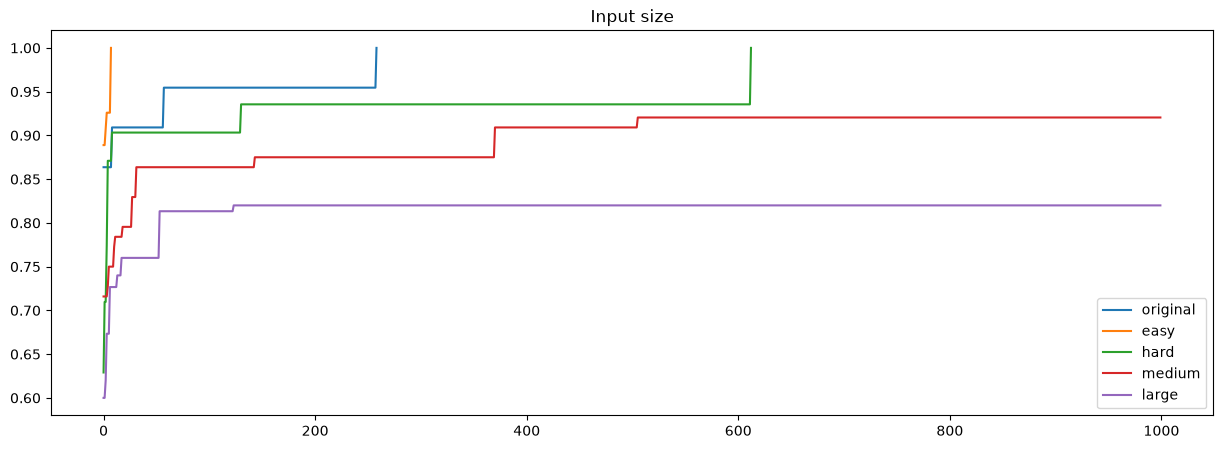

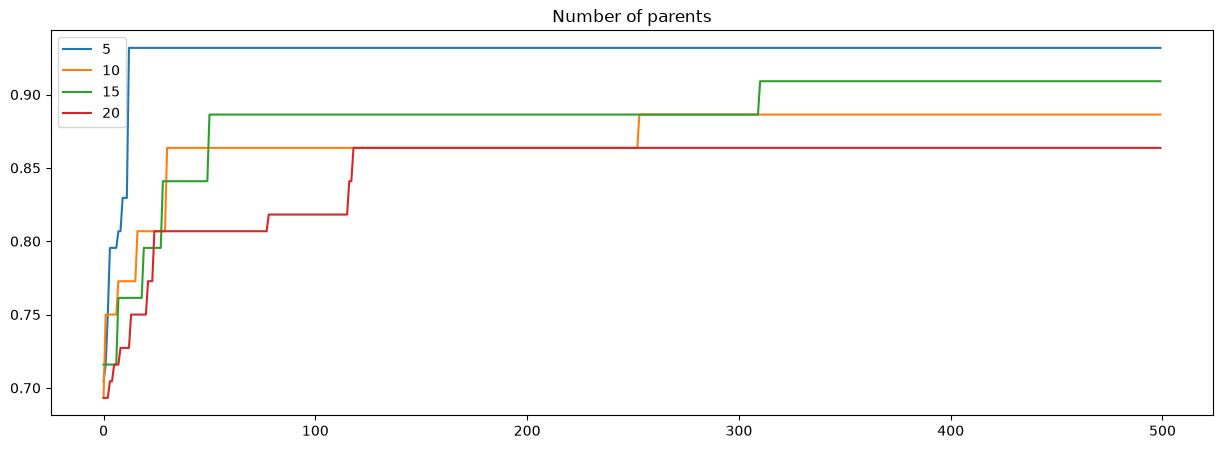

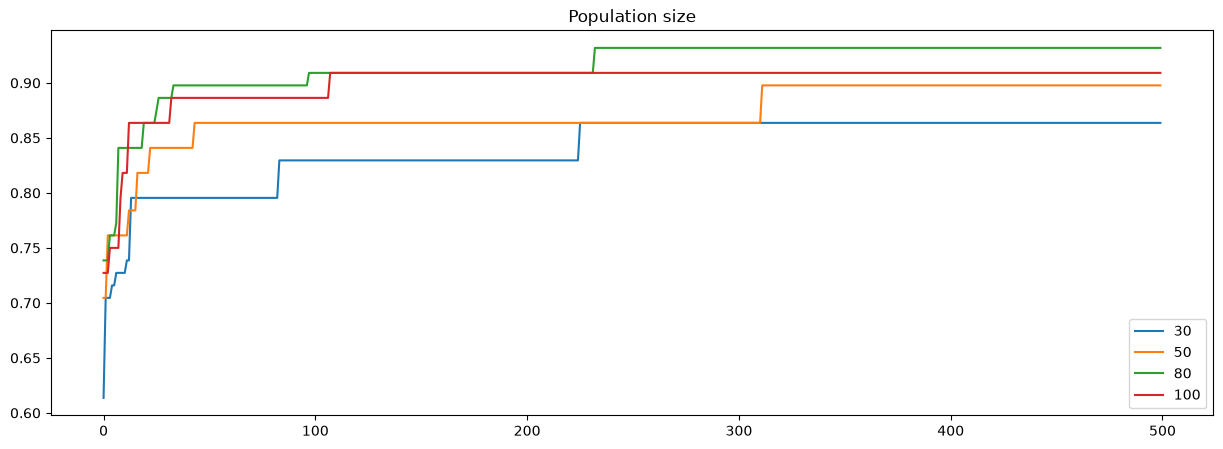

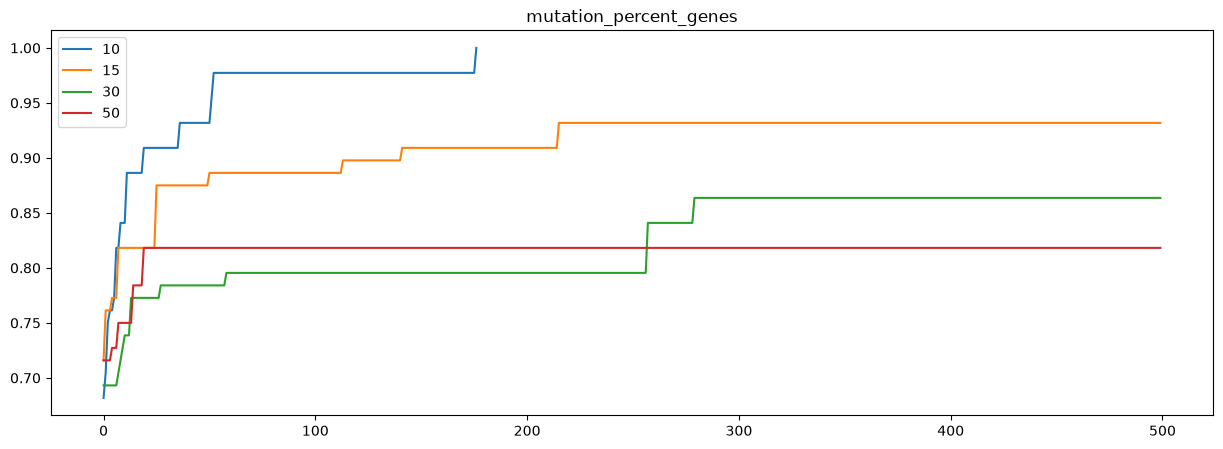

In [51]:
graph = []
task1('assets/original/', verbose=True, gen=1000)
print()
plt.figure(figsize=(15, 5)) 
plt.plot(graph, label='original')
for asset in ['assets/easy/', 'assets/hard/', 'assets/medium/', 'assets/large/']:
    graph = []
    task1(asset, gen=1000)
    plt.plot(graph, label=asset.split("/")[1])
plt.title("Input size")
plt.legend()
plt.show()

plt.figure(figsize=(15, 5)) 
for par in [5,10,15,20]:
    graph = []
    task1('assets/medium/', gen=500, parents=par)
    plt.plot(graph, label=str(par))
plt.title("Number of parents")
plt.legend()
plt.show()

plt.figure(figsize=(15, 5)) 
for pop in [30, 50, 80, 100]:
    graph = []
    task1('assets/medium/', gen=500, population=pop)
    plt.plot(graph, label=str(pop))
plt.title("Population size")
plt.legend()
plt.show()

plt.figure(figsize=(15, 5)) 
for mutation in [10, 15, 30, 50]:
    graph = []
    task1('assets/medium/', gen=500, population=100, mutation=mutation)
    plt.plot(graph, label=str(mutation))
plt.title("mutation_percent_genes")
plt.legend()
plt.show()

### <b>TASK 2</b>
<details>
<summary><b>Transcription of the conversation with AI about Task 2</b></summary>
Transkripcija pogovora z AI (Claude) – Seminarska naloga 1, Task 2
Datum: 28. 10. 2026
==================================================================

[UPORABNIK]
sedaj sem končal z prvo, preglej kodo, mislim da je to to. greva na drugo in ugotavljati kako bi jo izboljšala

[AI]
(prebere task1.py in ga trikrat požene s PyGAD 3.9.2)

Task 1 je v redu. task1.py sem trikrat pognal pri sebi s PyGAD 3.9.2, isto verzijo kot ti. Vsakič je našel popoln urnik 44/44, in sicer po 143, 298 in 299 generacijah. Zadnji urnik sem preveril tudi ročno: nobena učilnica in noben učitelj nimata prekrivanja. Napaka z return je odpravljena.

Tri drobnosti, preden zaključiš Task 1. Nobena ni napaka, vse pa bodo pomembne v Tasku 2:
- best_solution() v on_generation še vedno vsako generacijo na novo izračuna fitness celotne populacije. Ko boš meril čas posameznih korakov, ti bo to pokvarilo meritve.
- Ni random_seed. Že pri treh zagonih si videl razpon od 143 do 299 generacij. Kako boš ob takšnem šumu dokazal, da je izboljšava res boljša, in ne da si imel srečo?
- Izpis je po vrstnem redu predavanj. Za branje (in za predstavitev) bi bil bolj pregleden izpis po učilnicah in času. To je kozmetika, po želji.

Task 2

Navodila ponujajo dve smeri: boljšo začetno populacijo in svoja operatorja, crossover in mutacijo. Preden se lotiva katerekoli, odgovori na vprašanje 0: kaj pomeni "boljše"? Število generacij do 44, čas v sekundah, hitrost rasti fitnessa, delež zagonov, ki sploh dosežejo 44? Pri tako majhnem primeru, ki ga že osnovni GA reši v nekaj sto generacijah, bo razlika morda težko vidna. Kaj to pomeni za izbiro testnih podatkov?

Za vsako smer ti dam nekaj vprašanj za razmislek:

A) Začetna populacija (požrešno)
- Kaj v tvoji reprezentaciji pomeni "požrešno"? Kako bi predavanja polagal eno za drugim?
- Požrešni algoritem je deterministični. Če z njim narediš vseh 60 osebkov, kaj dobiš? Zakaj je to za GA slabo in kje lahko vneseš naključnost?
- Če požrešni algoritem že sam najde 44, kaj je potem GA sploh naredil? Kako boš to pošteno predstavil?

B) Mutacija
- Kaj zdaj naredi mutation_type="random"? Izbere naključne gene in jim da naključno vrednost, tudi genom predavanj, ki so že brez konflikta. Ali je smiselno popravljati nekaj, kar ni pokvarjeno?
- Kaj bi bila "pametnejša" mutacija? Kje je prava meja med pametno mutacijo in lokalnim iskanjem, ki izgubi raziskovanje?

C) Crossover
- Dokazala sva že, da single_point ne ustvari neveljavnega zapisa. Kaj pa je potem narobe z njim? Pomisli, ali vrstni red predavanj v kromosomu sploh kaj pomeni in kaj to pomeni za rez na eni točki.
- Ali lahko pri izbiri, kateri starš da posamezno predavanje, upoštevaš, kako "dobro" je to predavanje pri vsakem od staršev?

Predlagam, da začneva z A, ker je najbolj neodvisna od ostalega in jo je najlažje izmeriti. Lahko pa izbereš drugače. Najprej pa mi odgovori na vprašanje 0.

------------------------------------------------------------------

[UPORABNIK]
A) začetno rešitev bi naredil tako, da bi lepo po vrsti razporejal predavanja po urniku dokler gre, ko to ne gre več pa jih preprosto naključno razporedim. B) primerno je potrebno nujno menjati gene, ki se prekrivajo, tiste, ki se ne pa recimo le z 20% verjetnosti

[AI]
Obe ideji sta dobra izhodišča. Najprej opomba: vprašanje 0 si preskočil. Za zdaj ga pustiva, vendar se vrneva, preden karkoli meriš, ker brez njega Taska 2 ne moreš oceniti.

A) Požrešna začetna populacija

Ideja drži, manjkata pa dve stvari:

1. Raznolikost. Če "lepo po vrsti" vedno pomeni isti vrstni red in prvi prosti termin, je vseh 60 osebkov enakih do točke, kjer zmanjka prostora. GA s 60 kopijami istega osebka praktično nima česa križati. Kje v svojem postopku lahko vneseš naključnost, ne da bi izgubil požrešnost? Mesti sta vsaj dve.
2. Kateri vrstni red? Pomisli na problem pakiranja v zaboje. Ali je vseeno, ali najprej polagaš 2-urna ali 3-urna predavanja? Kaj se ponavadi zgodi s tistimi, ki pridejo na vrsto zadnja?

Še dve vprašanji:
- Ko "gre", ali preverjaš oba konflikta, učilnico in učitelja? Kako izbereš učitelja?
- Ali morajo biti vsi osebki požrešni, ali je smiselna mešanica, na primer del požrešnih in del naključnih? Zakaj?

B) Mutacija

Ta ideja mi je všeč. Usmeri mutacijo tja, kjer je problem. Vprašanja na podrobnosti:

1. V kaj spremeniš konflikten gen? V naključno vrednost, ki lahko spet povzroči konflikt, ali v vrednost, za katero preveriš, da konflikt odpravi? Druga možnost je hitrejša, vendar zdrsne v lokalno iskanje. Kje je za tebe meja?
2. Kateri od dveh genov? Če ima predavanje samo konflikt učitelja, ali res moraš premakniti termin? Tip konflikta ti pove, kateri gen spremeniti.
3. Obe predavanji v konfliktu? Če A in B trčita, ali premakneš obe? Kaj se zgodi, če premakneš obe hkrati?
4. 20 % za "zdrave" gene je po mojem precej. Pri 10 predavanjih bi pri vsakem potomcu v povprečju porušil približno dve dobri predavanji. Zakaj ravno 20? To bi moral biti parameter, ki ga v Tasku 4 preizkusiš na več vrednostih.

Dve praktični opombi za implementacijo:
- Mutacija mora vedeti, katera predavanja so v konfliktu, fitness pa trenutno vrne samo eno številko. Kako bi refaktoriral, da isto logiko zaznave uporabljata obe funkciji in je ne podvajaš?
- Preveri v dokumentaciji, ali PyGAD pri lastni mutaciji še upošteva gene_space. Po mojem ga ne. To pomeni, da moraš sam paziti, da vrednost ostane v dovoljeni domeni, sicer decode_chromosome pade z IndexError.

Odgovori na A1 in B1, ker sta to ključni odločitvi. Ostalo se bo razjasnilo ob kodiranju.

------------------------------------------------------------------

[UPORABNIK]
Za začetek naključnost vnesemo z mešanjem vrstnega reda dolgih predavanj in naključno izbiro med prostimi termini, pri čemer preverjamo oba trka in uporabimo mešanico osebkov za raznolikost. Pri mutaciji ciljno popravljamo le konfliktni gen enega predavanja brez povzročanja verižnih reakcij, 20-odstotno stopnjo pa je treba v Tasku 4 precej znižati, saj je preveč uničujoča.

[AI]
Obe odločitvi sta dobri. Mešanje znotraj skupin enakega trajanja, z dolgimi predavanji najprej, ohrani prednost požrešnega vrstnega reda in vseeno da raznolikost. Razmerje med požrešnimi in naključnimi osebki pa naj bo parameter, ne trdo zapisana številka. To je še en kandidat za primerjavo v Tasku 4.

Pri mutaciji imam dva ugovora:

1. Kaj, če vrednost brez konflikta ne obstaja? Na teh podatkih bo skoraj vedno obstajala. Na tesnih podatkih iz Taska 4 pa ne nujno. Kaj takrat naredi mutacija? Potrebuješ rezervno pot, ker sicer mutacija tiho ne naredi ničesar.
2. Popravljanje samo v vrednosti brez konflikta je lokalno iskanje. Predstavljaj si stanje, kjer ostane en konflikt in vsak posamezen premik predavanja povzroči nov konflikt. Rešitev bi bila, recimo, da dve predavanji zamenjata mesti. Ali tvoja mutacija iz takšnega stanja sploh lahko pobegne? Zato tistih "zdravih" genov ne smeš povsem zamrzniti. Nizka verjetnost naključne spremembe je točno tisto, kar ohranja raziskovanje.

Tudi trditev, da je 20 % preveč, je za zdaj samo hipoteza. Morda se izkaže, da je pri težkih vhodih ravno potrebna. Zapiši si jo kot vprašanje za Task 4, ne kot zaključek.

Za implementacijo potrebuješ iz PyGAD:
- initial_population=: seznam kromosomov, tvoja požrešna mešanica. Pazi, da je število osebkov enako sol_per_pop, oziroma preveri, kaj PyGAD naredi, če podaš oba parametra.
- mutation_type=tvoja_funkcija s podpisom (offspring, ga_instance), ki vrne spremenjen offspring.

Predlog vrstnega reda:
1. Refaktoriraj zaznavanje konfliktov v funkcijo, ki vrne konflikte po predavanjih. Fitness jo samo sešteje.
2. Implementiraj A in jo preizkusi samostojno: koliko fitnessa imajo začetni osebki v primerjavi z naključnimi?
3. Implementiraj B.
4. Nato vprašanje 0 in merjenje s callbacki.

Crossover (C) sva za zdaj preskočila. Navodila ga ne zahtevajo nujno ("possible ways include"), vendar ima tvoja reprezentacija tam zanimivo izboljšavo. Vrneva se k njemu, če bo čas.

Pokaži mi kodo, ko bosta A ali B napisana.

------------------------------------------------------------------

[UPORABNIK]
v task 2 je koda

[AI]
(prebere task2.py, ga 5-krat požene, v izvorni kodi PyGAD preveri, kdaj se izračuna last_generation_fitness, in ločeno izmeri fitness 60 požrešnih in 60 naključnih začetnih osebkov)

Kodo sem pognal pri sebi. Na kratko: A deluje, B še ni implementiran. Poleg tega se je zgodilo točno to, na kar sem opozarjal pri vprašanju 0.

Kaj sem naredil:
- task2.py sem pognal 5-krat. Vsakič je dosegel 44/44 v 1. generaciji.
- Ločeno sem izmeril začetne osebke, po 60 vsake vrste. Požrešni imajo v povprečju fitness 40,9 in 6 od 60 jih je že popolnih. Naključni imajo v povprečju 19,9, najboljši pa 30.
- V izvorni kodi PyGAD sem preveril, da je last_generation_fitness v on_generation že fitness nove populacije. Popravek tam je torej pravilen.

Ugotovitve

1. Mutacija (B) ni ciljana. Poglej obe veji v custom_mutation, vrstici 222–225. Kaj je razlika med njima? Trenutno je to isto kot mutation_type="random" z 15 %.

Vzrok sega korak nazaj: get_conflicts vrne eno številko za ves urnik. Mutacija pa mora vedeti, katero predavanje je v konfliktu in katerega tipa. Refaktor je torej narejen samo na pol. Kakšno strukturo naj vrne get_conflicts, da jo fitness lahko sešteje, mutacija pa uporabi po predavanjih?

2. A na teh podatkih reši problem sam. GA ni naredil ničesar, ker je popolni urnik obstajal že v začetni populaciji. To ni napaka v kodi, je pa problem za poročilo. Na teh podatkih ne moreš pokazati, da izboljšave pomagajo GA-ju. Pokažeš lahko samo, da je požrešni algoritem dober. Zato mi zdaj odgovori na vprašanje 0:
- Na katerih podatkih boš primerjal? Rabil boš vsaj en vhod, kjer požrešni algoritem ne najde popolne rešitve.
- Kako boš ločil prispevek A in B? Pomisli na kombinacije: osnova, samo A, samo B, A + B.

3. Manjše stvari:
- gene_space si odstranil iz pygad.GA. Zdaj deluje, ker ga sam upoštevaš v začetni populaciji in v mutaciji. Če pa boš za primerjavo "samo A" vklopil vgrajeno mutacijo, bo PyGAD generiral poljubna cela števila in decode_chromosome bo padel.
- Požrešni algoritem za vsakega kandidata pokliče get_conflicts na celotnem dosedanjem urniku. Ali res moraš preveriti vse pare, ali je dovolj preveriti samo novo predavanje proti že postavljenim? Na teh podatkih je vseeno, na velikih iz Taska 4 pa ne.
- Uporabljaš Pythonov modul random, random_seed v PyGAD pa nanj ne vpliva. Za ponovljive primerjave moraš nastaviti seme obema.

Predlagam, da najprej popraviš get_conflicts in mutacijo, potem pa se lotiva testnih podatkov in merjenja.

------------------------------------------------------------------

[UPORABNIK]
kako kaže sedaj s popravki

[AI]
(prebere posodobljeni task2.py, ga požene in naredi diagnostični test: naključna začetna populacija, 10 semen, do 2000 generacij, vgrajena random mutacija proti custom_mutation)

Popravki so v pravi smeri. get_lecture_conflicts zdaj vrne konflikte po predavanjih in po tipu, mutacija cilja pravi gen, evaluate_new_lecture preverja samo novo predavanje, gene_space in semena so nastavljeni. Ostale so tri vsebinske stvari, ena pa je zelo zanimiva.

Kaj sem naredil: task2.py sem pognal tak, kot je. Spet je dosegel 44 v 1. generaciji, ker požrešna populacija problem že reši. Da bi videl učinek samo mutacije B, sem naredil hiter diagnostični test: naključna začetna populacija, 10 semen, do 2000 generacij. Primerjal sem vgrajeno random mutacijo s tvojo custom_mutation. Rezultat je število generacij do 44:

    random: [288, 64, 532, 130, 186, 21, 382, 242, 358, 32]   → 10/10 doseže 44
    custom: [5, 2000, 9, 10, 15, 1598, 732, 2000, 13, 8]       → 8/10 doseže 44

Tvoja mutacija je bimodalna. V večini primerov je za velikostni razred hitrejša (5–15 generacij), včasih pa se zatakne za stotine generacij ali sploh ne konča. To ni slab rezultat, ampak odličen material za poročilo, če znaš razložiti, zakaj se to zgodi.

Zakaj se zatakne? Ne teoretiziraj. Dodaj diagnostiko: ko fitness N generacij stoji, izpiši najboljši urnik in njegove lect_confs. Pri tem razmisli o treh stvareh v kodi:

1. Zastarel seznam konfliktov. lect_confs izračunaš enkrat, pred mutacijo. Recimo, da A in B trčita in v zanki premakneš A. Kaj se zgodi, ko zanka pride do B? To je točno vprašanje "obe predavanji v konfliktu?" od prej.
2. Mutacija v naključno vrednost. Rekel si, da boš konfliktni gen popravil brez verižnih reakcij. Koda pa izbere random.choice(gene_space[...]), kar lahko ustvari nov konflikt. Je to zavestna odločitev ali razlika med idejo in kodo?
3. Raziskovanje. Zdravo predavanje se spremeni s ~3 % verjetnosti. Ko se populacija zbere okoli enega skoraj popolnega urnika, ali je to dovolj, da pobegne? Spomni se primera, kjer bi morali dve predavanji zamenjati mesti.

Za vsako od teh lahko napišeš varianto in jo primerjaš. Ta primerjava je že vsebina Taska 2 in 4.

Manjše stvari:
- Konfliktno predavanje se mutira samo s 15 % verjetnosti. Prej si rekel "nujno menjati". Kaj je zdaj prav?
- Na koncu task2.py ni več izpisa končnega urnika.
- Mutacijski parametri (0,15 in 0,2) so trdo zapisani v funkciji. Za Task 4 jih boš želel spreminjati od zunaj.

Najprej dodaj diagnostiko za zatikanje in mi povej, kaj vidiš.

------------------------------------------------------------------

[UPORABNIK]
tej kodi v task2 dodaj te nonlocalne parametre na začetek in izpis urnika, potem napiši transkripcijo najinega pogovora in jo shrani v mapo, kjer se ta transkripcija začne od mojega sporočila: "sedaj sem končal z prvo, preglej kodo, mislim da je to to. greva na drugo in ugotavljati kako bi jo izboljšala" naprej

[AI]
(v task2.py doda na začetek nonlocalne parametre GREEDY_RATIO = 0.7, MUTATION_RATE = 0.15 in HEALTHY_MUTATION_FACTOR = 0.2 ter jih uporabi namesto trdo zapisanih vrednosti v generate_greedy_chromosome, pri gradnji initial_population in v custom_mutation; na konec doda izpis končnega fitnessa in urnika v enaki obliki kot v task1.py; kodo požene in preveri, da deluje; zapiše to datoteko)

</details>

In [38]:
RANDOM_SEED = 42
random.seed(RANDOM_SEED)

# nonlocalni parametri GA
GREEDY_CHROMOSOMES = 1             # število požrešnih osebkov v začetni populaciji
MUTATION_RATE = 0.9          # verjetnost mutacije konfliktnega predavanja
HEALTHY_MUTATION_FACTOR = 0.9  # zdrava predavanja se mutirajo z MUTATION_RATE * HEALTHY_MUTATION_FACTOR

ASSETS_PATH = 'assets/large/'

In [39]:
def task2(asset, gen=200):
    classes, classrooms, teachers, preferences = load_data(asset)
    valid_terms_by_duration = {}
    all_durations = set(c['duration'] for c in classes)

    for d in all_durations:
        terms = []
        for cr_name, cr_range in classrooms.items():
            op = cr_range['start']
            cl = cr_range['end']
            for start in range(op, cl - d + 1):
                terms.append((cr_name, start))
        valid_terms_by_duration[d] = terms

    gene_space = []
    eligible_teachers_per_lecture = []

    for c in classes:
        d = c['duration']
        subj = c['subject']

        num_terms = len(valid_terms_by_duration[d])
        gene_space.append(list(range(num_terms)))

        elig_teach = [t for t, subs in teachers.items() if subj in subs]
        eligible_teachers_per_lecture.append(elig_teach)

        gene_space.append(list(range(len(elig_teach))))


    def decode_chromosome(solution):
        schedule = []
        for i, c in enumerate(classes):
            term_idx = int(solution[2 * i])
            teacher_idx = int(solution[2 * i + 1])

            d = c['duration']
            subj = c['subject']

            cr_name, start = valid_terms_by_duration[d][term_idx]
            teacher_name = eligible_teachers_per_lecture[i][teacher_idx]

            schedule.append({
                'subject': subj,
                'duration': d,
                'classroom': cr_name,
                'start': start,
                'end': start + d,
                'teacher': teacher_name
            })
        return schedule


    total_hours = sum(c['duration'] for c in classes)
    max_fitness = 2 * total_hours


    def get_lecture_conflicts(schedule):
        conflicts_per_lecture = []
        for i, lec in enumerate(schedule):
            l_start = lec['start']
            l_end = lec['end']
            l_room = lec['classroom']
            l_teacher = lec['teacher']

            room_conflicts = 0
            teacher_conflicts = 0

            for hour in range(l_start, l_end):
                room_hit = False
                teacher_hit = False

                for j, other in enumerate(schedule):
                    if i == j:
                        continue
                    if other['start'] <= hour < other['end']:
                        if other['classroom'] == l_room:
                            room_hit = True
                        if other['teacher'] == l_teacher:
                            teacher_hit = True

                if room_hit:
                    room_conflicts += 1
                if teacher_hit:
                    teacher_conflicts += 1

            conflicts_per_lecture.append({
                'room': room_conflicts,
                'teacher': teacher_conflicts,
                'total': room_conflicts + teacher_conflicts
            })
        return conflicts_per_lecture


    def fitness_func(ga_instance, solution, solution_idx):
        schedule = decode_chromosome(solution)
        lect_confs = get_lecture_conflicts(schedule)
        total_conflicts = sum(c['total'] for c in lect_confs)
        score = max_fitness - total_conflicts
        return float(score)


    def evaluate_new_lecture(temp_lec, assigned_schedule):
        conf = 0
        for hour in range(temp_lec['start'], temp_lec['end']):
            r_hit = False
            t_hit = False
            for other in assigned_schedule:
                if other['start'] <= hour < other['end']:
                    if other['classroom'] == temp_lec['classroom']:
                        r_hit = True
                    if other['teacher'] == temp_lec['teacher']:
                        t_hit = True
            if r_hit:
                conf += 1
            if t_hit:
                conf += 1
        return conf


    def generate_greedy_chromosome():
        indexed_classes = list(enumerate(classes))
        grouped = {}
        for idx, c in indexed_classes:
            grouped.setdefault(c['duration'], []).append((idx, c))

        sorted_indices = []
        for d in sorted(grouped.keys(), reverse=True):
            group = grouped[d]
            random.shuffle(group)
            sorted_indices.extend(group)

        solution = [0] * (len(classes) * 2)
        assigned_schedule = []

        for i, c in sorted_indices:
            d = c['duration']
            possible_terms = list(enumerate(valid_terms_by_duration[d]))
            random.shuffle(possible_terms)

            elig_teach = eligible_teachers_per_lecture[i]
            teach_indices = list(range(len(elig_teach)))
            random.shuffle(teach_indices)

            best_term_idx = possible_terms[0][0]
            best_teach_idx = teach_indices[0]
            min_conflicts = float('inf')

            for t_idx, (cr_name, start) in possible_terms:
                for th_idx in teach_indices:
                    temp_lec = {
                        'subject': c['subject'],
                        'duration': d,
                        'classroom': cr_name,
                        'start': start,
                        'end': start + d,
                        'teacher': elig_teach[th_idx]
                    }
                    conf = evaluate_new_lecture(temp_lec, assigned_schedule)
                    if conf < min_conflicts:
                        min_conflicts = conf
                        best_term_idx = t_idx
                        best_teach_idx = th_idx
                    if min_conflicts == 0:
                        break
                if min_conflicts == 0:
                    break

            solution[2 * i] = best_term_idx
            solution[2 * i + 1] = best_teach_idx

            cr_name, start = valid_terms_by_duration[d][best_term_idx]
            assigned_schedule.append({
                'subject': c['subject'],
                'duration': d,
                'classroom': cr_name,
                'start': start,
                'end': start + d,
                'teacher': elig_teach[best_teach_idx]
            })

        return solution


    sol_per_pop = 80
    initial_population = [generate_greedy_chromosome() for _ in range(GREEDY_CHROMOSOMES)]
    initial_population.extend([[random.choice(space) for space in gene_space] for _ in range(sol_per_pop - GREEDY_CHROMOSOMES)])


    def custom_mutation(offspring, ga_instance):
        mutation_rate = MUTATION_RATE
        for idx in range(offspring.shape[0]):
            chromosome = offspring[idx]
            schedule = decode_chromosome(chromosome)
            lect_confs = get_lecture_conflicts(schedule)

            for i, conf in enumerate(lect_confs):
                # Če ima predavanje konflikt, ciljano napademo napačen gen
                if conf['room'] > 0 or conf['teacher'] > 0:
                    if random.random() < mutation_rate:
                        if conf['room'] > 0 and conf['teacher'] > 0:
                            gene_to_mutate = random.choice([2 * i, 2 * i + 1])  # izberemo naključno enega od obeh
                        elif conf['room'] > 0:
                            gene_to_mutate = 2 * i  # napaka je v učilnici/terminu
                        else:
                            gene_to_mutate = 2 * i + 1  # napaka je pri učitelju

                        chromosome[gene_to_mutate] = random.choice(gene_space[gene_to_mutate])
                else:
                    # Za "zdrave" gene ohranimo nizko naključno raziskovanje (npr. 20% od mutation_rate)
                    if random.random() < (mutation_rate * HEALTHY_MUTATION_FACTOR):
                        gene_to_mutate = random.choice([2 * i, 2 * i + 1])
                        chromosome[gene_to_mutate] = random.choice(gene_space[gene_to_mutate])

        return offspring

    start_time = None
    gen_time = time.perf_counter()
    mutation_times = []
    crossover_times = []
    generation_times = []


    def on_generation(ga_instance):
        nonlocal start_time, gen_time
        end_time = time.perf_counter()
        generation_times.append(end_time - gen_time)
        gen_time = end_time
        start_time = end_time
        best_fit = ga_instance.best_solution(ga_instance.last_generation_fitness)[1]
        graph.append(best_fit/max_fitness)
        if best_fit >= max_fitness:
            return "stop"

    def on_parents(ga_instance, parents):
        nonlocal start_time
        start_time = time.perf_counter()

    def on_crossover(ga_instance, offspring):
        nonlocal start_time
        end_time = time.perf_counter()
        crossover_times.append(end_time - start_time)
        start_time = end_time

    def on_mutation(ga_instance, offspring):
        nonlocal start_time
        end_time = time.perf_counter()
        mutation_times.append(end_time - start_time)
        start_time = end_time


    ga_instance = pygad.GA(
        num_generations=gen,
        num_parents_mating=10,
        fitness_func=fitness_func,
        sol_per_pop=sol_per_pop,
        initial_population=initial_population,
        gene_space=gene_space,
        num_genes=len(classes) * 2,
        gene_type=int,
        parent_selection_type="sss",
        crossover_type="single_point",
        mutation_type=custom_mutation,
        random_seed=RANDOM_SEED,
        on_generation=on_generation,
        on_parents=on_parents,
        on_crossover=on_crossover,
        on_mutation=on_mutation
    )

    ga_instance.run()

    return [sum(mutation_times)/len(mutation_times), sum(crossover_times)/len(crossover_times), sum(generation_times)/len(generation_times)]


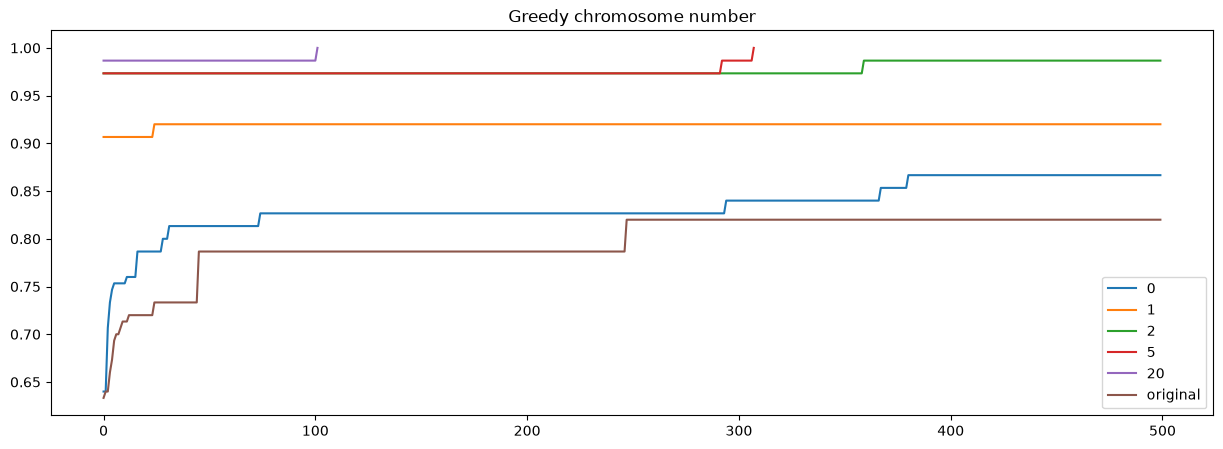

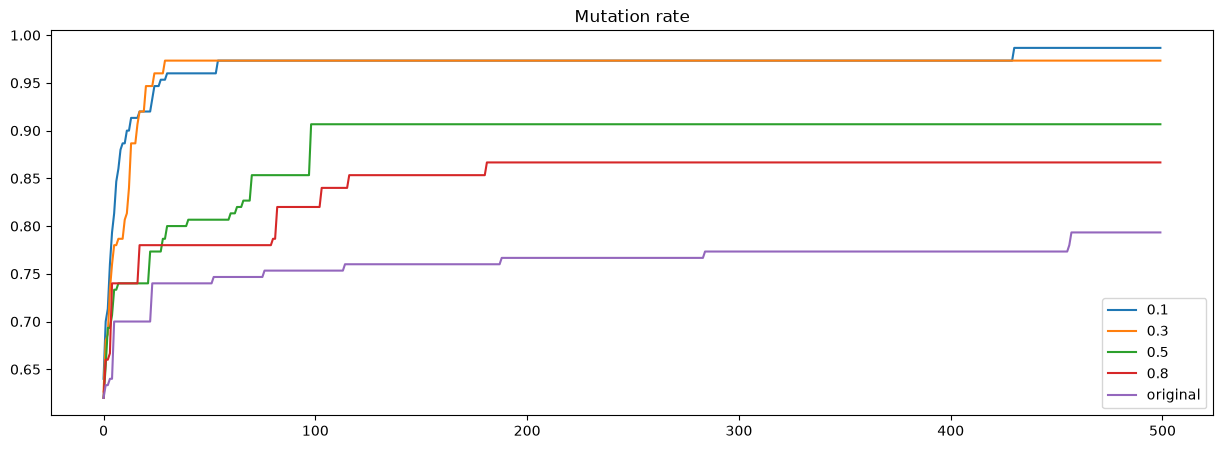

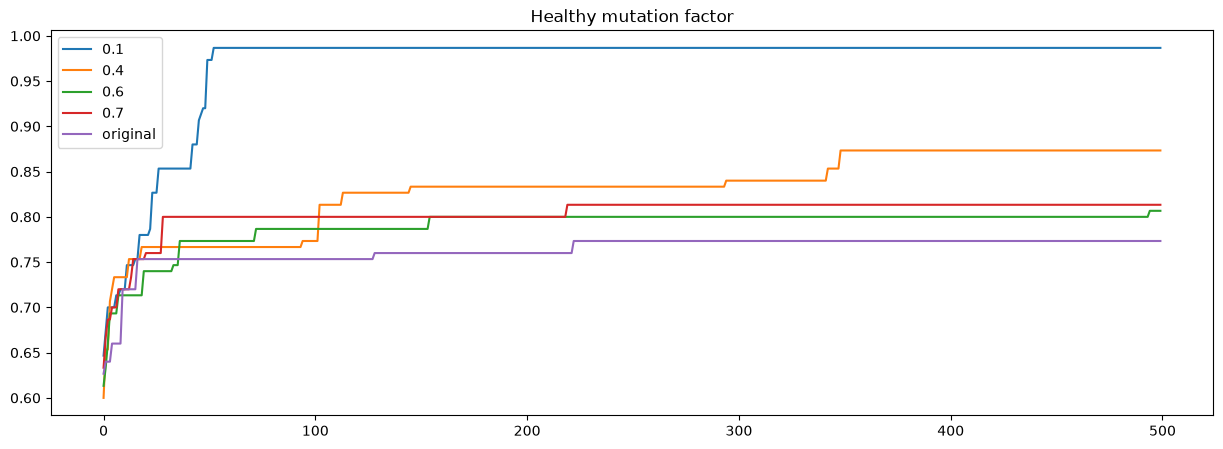

In [ ]:
RANDOM_SEED = 50
random.seed(RANDOM_SEED)

# globalni parametri GA
GREEDY_CHROMOSOMES = 0             # delež požrešnih osebkov v začetni populaciji
MUTATION_RATE = 0.8         # verjetnost mutacije konfliktnega predavanja
HEALTHY_MUTATION_FACTOR = 0.1  # zdrava predavanja se mutirajo z MUTATION_RATE * HEALTHY_MUTATION_FACTOR

ASSETS_PATH = 'assets/large/'

plt.figure(figsize=(15, 5)) 
for greedy in [0, 1, 2, 5, 20]:
    GREEDY_CHROMOSOMES = greedy
    graph = []
    task2(ASSETS_PATH, gen=500)
    plt.plot(graph, label=greedy)
graph = []
task1(ASSETS_PATH, gen=500)
plt.title("Greedy chromosome number")
plt.plot(graph, label="original")
plt.legend()
plt.show()

plt.figure(figsize=(15, 5)) 
GREEDY_CHROMOSOMES = 0
HEALTHY_MUTATION_FACTOR = 0.4
for rate in [0.1, 0.3, 0.5, 0.8]:
    MUTATION_RATE = rate
    graph = []
    task2(ASSETS_PATH, gen=500)
    plt.plot(graph, label=rate)
graph = []
task1(ASSETS_PATH, gen=500)
plt.plot(graph, label="original")
plt.title("Mutation rate")
plt.legend()
plt.show()

plt.figure(figsize=(15, 5)) 
MUTATION_RATE= 0.6
for factor in [0.1, 0.4, 0.6, 0.7]:
    HEALTHY_MUTATION_FACTOR = factor
    graph = []
    task2(ASSETS_PATH, gen = 500)
    plt.plot(graph, label=factor)
graph = []
task1(ASSETS_PATH, gen=500)
plt.plot(graph, label="original")
plt.title("Healthy mutation factor")
plt.legend()
plt.show()

### <b>TASK 3</b>

<details>
<summary><b>Transcription of the conversation with AI about Task 3</b></summary>

TRANSKRIPCIJA POGOVORA – TASK 3


#### UPORABNIK


Preberi si nalogo, nato se bova o njej pogovorila, ne piši kode. During this task, you will implement two additional constraints on the schedul
ing algorithm. Unlike the constraints in Task 1, these are soft constraints: the
schedule does not need to satisfy them 100% to be valid, but satisfying them
should increase the fitness score. The additional constraints are:
• Teacher preferences. Your scheduling program should now consider
an additional file preferences.txt, which describes when teachers would
like to teach their classes. Each line in the file contains the teacher’s name
followed by a dictionary of preferences in the form:
Miha {”likes” : [start hour,end hour],”dislikes” : [start hour,end hour]}.
Your algorithm should attempt to follow these preferences by placing each
teacher’s lectures during hours they like and outside the hours they dislike.
• Teacher balance. The schedule should balance the teaching hours be
tween the teachers so that everyone teaches (approximately) the same
number of hours. This may not always be possible, but the algorithm should
balance the hours as much as possible.
Tackle these two constraints in two ways:
• Using a single fitness function that takes into account both constraints.
• Using multi objective optimization. PyGAD supports this with a few
small tweaks to the algorithm described here:
https://pygad.readthedocs.io/en/latest/multi_objective.html.
As in Task 2, evaluate the approach and present the results as described in
Task 4.


#### ASISTENT


Prebral sem nalogo. Razumem, kaj je treba narediti. Kode za zdaj ne bom pisal.

Naloga zahteva nadgradnjo obstoječega algoritma za izdelavo urnikov z **dvema dodatnima mehkima omejitvama (soft constraints)**.

 1. Preference učiteljev (Teacher preferences)

Dodati je treba datoteko `preferences.txt`, v kateri je za vsakega učitelja določeno:

- `likes`: časovni interval, v katerem učitelj želi poučevati.
- `dislikes`: časovni interval, v katerem učitelj ne želi poučevati.

Primer iz naloge:

`Miha {"likes": [start hour, end hour], "dislikes": [start hour, end hour]}`

Algoritem naj poskuša razporediti učiteljeve ure v njemu ustreznejše termine in se izogibati terminom, ki jih ne mara.

avnoteženost obremenitve učiteljev (Teacher balance)

Algoritem naj poskuša doseči, da imajo vsi učitelji približno enako število pedagoških ur.

Popolna enakost ni nujna, saj zaradi različnih predmetov, trajanj predavanj in razpoložljivosti učiteljev morda ni izvedljiva. Pomembno je, da algoritem čim bolj zmanjša razlike v obremenitvi.

lementacije

Obe novi omejitvi moramo implementirati na dva različna načina:

**Prvi pristop: Single fitness function**

Obe omejitvi vključimo v eno funkcijo fitness. Ta mora upoštevati:
- konflikte učilnic in učiteljev;
- zadovoljstvo učiteljev z razporejenimi termini;
- uravnoteženost števila pedagoških ur.

Vse skupaj vpliva na eno skupno oceno urnika.

**Drugi pristop: Multi-objective optimization**

Namesto ene skupne ocene uporabimo več ciljev optimizacije. PyGAD omogoča večciljno optimizacijo, pri kateri se posamezni cilji ocenjujejo ločeno.

Za ta pristop moramo prilagoditi obstoječi algoritem skladno z dokumentacijo PyGAD, ki jo navaja naloga.

ja rezultatov

Na koncu moramo oba pristopa ovrednotiti in predstaviti rezultate po navodilih iz Task 4.

---

**Pomembno za najino nadaljnjo razpravo:** ne gre samo za dodajanje dveh novih pogojev v obstoječo funkcijo fitness. Naloga zahteva primerjavo dveh različnih pristopov optimizacije, ki upoštevata iste dodatne omejitve.

Osnovni algoritem za razporejanje predavanj ostaja izhodišče, ki ga bova nadgradila.


#### UPORABNIK


Piši krajše odgovore. Ali bi bila dobra ideja, da trenutni fitness pomnožimo s 100 za večje omejitve, te šibkejše omejitve pri tretji nalogi pa bi bila manjša števila, ki jih odštevamo od fitnessa


#### ASISTENT


Da, to je dobra ideja. Predlagam pristop z **uteževanjem (weighted fitness)**, pri katerem imajo osnovne omejitve bistveno večjo težo kot novi mehki omejitvi.

Na primer:

Fitness = 100 × Fitness_osnovni − Penalty_preferences − Penalty_balance

Kjer:

- **Osnovni fitness × 100:** zagotavlja, da so konflikti učiteljev in učilnic veliko bolj nezaželeni.
- **Preference penalty:** manjše kazenske točke za razporejanje učiteljev v nezaželene termine oziroma nagrajevanje želenih terminov.
- **Balance penalty:** kazenske točke glede na razlike v številu pedagoških ur med učitelji.

**Pomembna podrobnost:** uteži moramo izbrati tako, da izboljšanje mehkih omejitev ne more odtehtati enega dodatnega konflikta iz osnovnih omejitev.

Zato bi najprej določil maksimalno možno kazen za obe mehki omejitvi in na tej podlagi izbral uteži.

Tak pristop je smiseln za prvo različico naloge. Pri drugi različici pa bomo iste cilje obravnavali ločeno z multi-objective optimization.


#### UPORABNIK


Ok, kaj pa za tisto multi objective optimization? Bi naredil ločeni fitness funkciji za močne in šibke omejitve, pri čemer je dominantna tista z močnimi, ob enaki vrednosti pa se gleda fitness šibkejših?


#### ASISTENT


Ideja z dvema ločenima fitness funkcijama je pravilna, vendar je ena pomembna razlika.

V **PyGAD Multi-objective optimization (NSGA-II)** se cilji ne obravnavajo po prioriteti. Algoritem jih obravnava kot enakovredne cilje in išče kompromis med njimi.

Predlagal bi:

**Fitness 1 – Strong constraints**
- Konflikti učilnic.
- Konflikti učiteljev.
- Cilj: čim višja ocena oziroma nič konfliktov.

**Fitness 2 – Soft constraints**
- Upoštevanje preferenc učiteljev.
- Uravnoteženost pedagoških ur.
- Cilj: čim boljše zadovoljstvo obeh pogojev.

Fitness funkcija bi torej vračala dve vrednosti, ki ju PyGAD optimizira ločeno.

**Pomembna razlika:**

Tvoja ideja, da se najprej optimizira prvi fitness, drugega pa upošteva samo ob enaki vrednosti prvega, se imenuje *lexicographic optimization*.

To ni običajno obnašanje NSGA-II.

Moje priporočilo: za nalogo uporabiva dve ločeni oceni in NSGA-II, da pravilno implementirava večciljno optimizacijo. Nato primerjava rezultate s prvo metodo, kjer uporabljava uteženo skupno fitness funkcijo.

Tako bova lahko tudi analizirala, ali večciljna optimizacija doseže boljše kompromise med omejitvami.


#### UPORABNIK


Kako pa naj dosežem kompromis med omejitvami, če so ene bistveno pomembnejše od drugih


#### ASISTENT


V tem primeru morava ločiti med **iskanjem kompromisa** in **določanjem prioritet**.

Pri NSGA-II v PyGAD so cilji privzeto enakovredni. Algoritem išče Pareto optimalne rešitve, ne pa rešitve, ki bi samodejno dala prednost prvemu fitnessu.

Predlagam naslednji pristop:

tive fitness z absolutno prioriteto osnovnih omejitev

Uporabimo dve ločeni fitness funkciji:

**Fitness 1 – Preference**
- Upoštevanje želja učiteljev.
- Kazen za nezaželene termine.

**Fitness 2 – Balance**
- Uravnoteženost pedagoških ur med učitelji.

V obe funkciji pa vključimo še zelo veliko kazen za kršenje osnovnih omejitev.

Na primer:

F₁ = PreferenceScore − M × Conflicts

F₂ = BalanceScore − M × Conflicts

`M` je dovolj velika konstanta, da nobena izboljšava mehkih omejitev ne more nadomestiti dodatnega konflikta.

Tako dosežemo:
1. Najprej imajo prednost urniki brez konfliktov.
2. Med urniki z enakim številom konfliktov se iščejo boljše preference in uravnoteženost.
3. Med enako dobrimi rešitvami glede enega cilja lahko algoritem išče kompromise glede drugega.

**Moje priporočilo:** To je primeren pristop za tvojo nalogo. Tako ohraniva multi-objective optimization, hkrati pa zagotoviva, da so osnovne omejitve bistveno pomembnejše od mehkih.


#### UPORABNIK


Torej enako kot v prejšnjem primeru, le da sta zdaj to dve ločeni funkciji za vsako šibko omejitev posebej, medtem ko so močne omejitve uporabljene pri obeh?


#### ASISTENT


Tako je. Razlika je samo v tem, da pri multi-objective pristopu mehki omejitvi obravnavamo ločeno.

Uporabimo dve fitness funkciji:

**Fitness 1 – Teacher preferences**

F₁ = 100 × F_strong + F_preferences

**Fitness 2 – Teacher balance**

F₂ = 100 × F_strong + F_balance

Obe torej upoštevata močne omejitve, vendar vsaka optimizira svojo mehko omejitev.

S tem dosežemo:
- Močne omejitve imajo prednost v obeh funkcijah.
- Prva funkcija izboljšuje preference učiteljev.
- Druga funkcija izboljšuje uravnoteženost pedagoških ur.
- NSGA-II išče rešitve, ki predstavljajo kompromise med obema ciljema.

**Pomembno:** faktor 100 moramo ustrezno določiti glede na razpone vseh ocen, da izboljšanje mehke omejitve ne more upravičiti dodatnega konflikta.


#### UPORABNIK


Zapiši celotno transkripcijo pogovora o Task 3 in mi vrni txt datoteko.

</details>

In [43]:
    
def task3(asset, mode, gen=200, verbose=False):
    classes, classrooms, teachers, preferences = load_data(asset)
    valid_terms_by_duration = {}
    all_durations = set(c['duration'] for c in classes)

    for d in all_durations:
        terms = []
        for cr_name, cr_range in classrooms.items():
            op = cr_range['start']
            cl = cr_range['end']
            for start in range(op, cl - d + 1):
                terms.append((cr_name, start))
        valid_terms_by_duration[d] = terms

    gene_space = []
    eligible_teachers_per_lecture = []

    for c in classes:
        d = c['duration']
        subj = c['subject']

        num_terms = len(valid_terms_by_duration[d])
        gene_space.append(list(range(num_terms)))

        elig_teach = [t for t, subs in teachers.items() if subj in subs]
        eligible_teachers_per_lecture.append(elig_teach)

        gene_space.append(list(range(len(elig_teach))))


    def decode_chromosome(solution):
        schedule = []
        for i, c in enumerate(classes):
            term_idx = int(solution[2 * i])
            teacher_idx = int(solution[2 * i + 1])

            d = c['duration']
            subj = c['subject']

            cr_name, start = valid_terms_by_duration[d][term_idx]
            teacher_name = eligible_teachers_per_lecture[i][teacher_idx]

            schedule.append({
                'subject': subj,
                'duration': d,
                'classroom': cr_name,
                'start': start,
                'end': start + d,
                'teacher': teacher_name
            })
        return schedule


    total_hours = sum(c['duration'] for c in classes)
    max_fitness = 2 * total_hours
    max_penatly = 2 * total_hours # En profesor uči vse in ne mara nobene ure
    decimals = math.ceil(math.log10(max_penatly)+1)
    weight = 10 ** decimals

    def teachers_preferences(schedule):
        total = 0
        for c in schedule:
            wishes = preferences[c["teacher"]]
            total += max(0, min(c["end"], wishes["likes"][1]) - max(c["start"], wishes["likes"][0]))
            total -= max(0, min(c["end"], wishes["dislikes"][1]) - max(c["start"], wishes["dislikes"][0]))
        return total


    def balance(schedule):
        result = 0
        hours = sum(c['duration'] for c in classes)
        avg = hours / len(teachers)
        teaching_hours = {name : 0 for name in list(teachers.keys())}
        for c in schedule:
            teaching_hours[c["teacher"]] += c["duration"]
        for work in teaching_hours.values():
            result -= abs(avg-work)
        return result


    def fitness_func(ga_instance, solution, solution_idx):
        schedule = decode_chromosome(solution)
        score = 0

        for i, lec in enumerate(schedule):
            l_start = lec['start']
            l_end = lec['end']
            l_room = lec['classroom']
            l_teacher = lec['teacher']

            for hour in range(l_start, l_end):
                room_conflict = False
                teacher_conflict = False

                for j, other in enumerate(schedule):
                    if i == j:
                        continue
                    if other['start'] <= hour < other['end']:
                        if other['classroom'] == l_room:
                            room_conflict = True
                        if other['teacher'] == l_teacher:
                            teacher_conflict = True

                if not room_conflict:
                    score += 1
                if not teacher_conflict:
                    score += 1
        if mode == 1:
            score += teachers_preferences(schedule) / weight
            score += balance(schedule) / weight
            return float(score)
        else:
            score1 = score2 = score
            score1 += teachers_preferences(schedule) / weight
            score2 += balance(schedule) / weight
            return [float(score1), float(score2)]

    start_time = None
    gen_time = time.perf_counter()
    mutation_times = []
    crossover_times = []
    generation_times = []

    def on_generation(ga_instance):
        nonlocal start_time, gen_time
        end_time = time.perf_counter()
        generation_times.append(end_time - gen_time)
        gen_time = end_time
        start_time = end_time
        best_fit = ga_instance.best_solution()[1]
        if mode == 1:
            graph.append(best_fit/max_fitness)
        else:
            graph.append(sum(list(best_fit))/(2*max_fitness))
        if verbose:
            if mode == 1:
                print("Fitness function: ", round(best_fit,decimals))
            else:
                print(f"Fitness function: ({round(best_fit[0],decimals)}, {round(best_fit[1], decimals)})")

    def on_parents(ga_instance, parents):
        nonlocal start_time
        start_time = time.perf_counter()

    def on_crossover(ga_instance, offspring):
        nonlocal start_time
        end_time = time.perf_counter()
        crossover_times.append(end_time - start_time)
        start_time = end_time

    def on_mutation(ga_instance, offspring):
        nonlocal start_time
        end_time = time.perf_counter()
        mutation_times.append(end_time - start_time)
        start_time = end_time


    ga_instance = pygad.GA(
        num_generations=gen,
        num_parents_mating=10,
        fitness_func=fitness_func,
        sol_per_pop=80,
        num_genes=len(classes) * 2,
        gene_space=gene_space,
        gene_type=int,
        parent_selection_type="sss" if mode == 1 else "nsga2",
        crossover_type="single_point",
        mutation_type="random",
        mutation_percent_genes=15,
        on_generation=on_generation,
        on_parents=on_parents,
        on_crossover=on_crossover,
        on_mutation=on_mutation
    )

    ga_instance.run()

    return [sum(mutation_times)/len(mutation_times), sum(crossover_times)/len(crossover_times), sum(generation_times)/len(generation_times)]

Fitness function:  31.999
Fitness function:  31.999
Fitness function:  33.996
Fitness function:  34.004
Fitness function:  34.004
Fitness function:  34.004
Fitness function:  34.004
Fitness function:  34.004
Fitness function:  41.994
Fitness function:  41.994
Fitness function:  41.994
Fitness function:  41.994
Fitness function:  44.0
Fitness function:  44.0
Fitness function:  44.0
Fitness function:  44.0
Fitness function:  44.0
Fitness function:  44.0
Fitness function:  44.0
Fitness function:  44.0
Fitness function:  44.0
Fitness function:  44.0
Fitness function:  44.0
Fitness function:  44.0
Fitness function:  44.0
Fitness function:  44.0
Fitness function:  44.0
Fitness function:  44.0
Fitness function:  44.0
Fitness function:  44.0
Fitness function:  44.0
Fitness function:  44.0
Fitness function:  44.0
Fitness function:  44.0
Fitness function:  44.0
Fitness function:  44.0
Fitness function:  44.0
Fitness function:  44.0
Fitness function:  44.0
Fitness function:  44.0
Fitness function

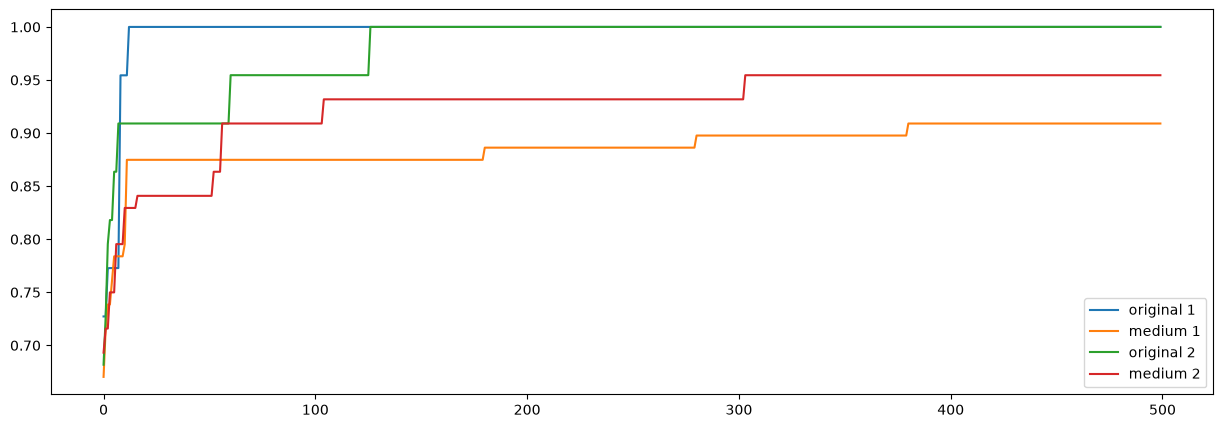

In [47]:
plt.figure(figsize=(15, 5)) 
for mode in [1,2]:
    graph = []
    task3('assets/original/', mode, gen=500, verbose =True)
    plt.plot(graph, label="original " + str(mode))
    graph = []
    task3('assets/medium/', mode, gen=500)
    plt.plot(graph, label=("medium " + str(mode)))
plt.legend()
plt.show()

### <b>Time consumption</b>

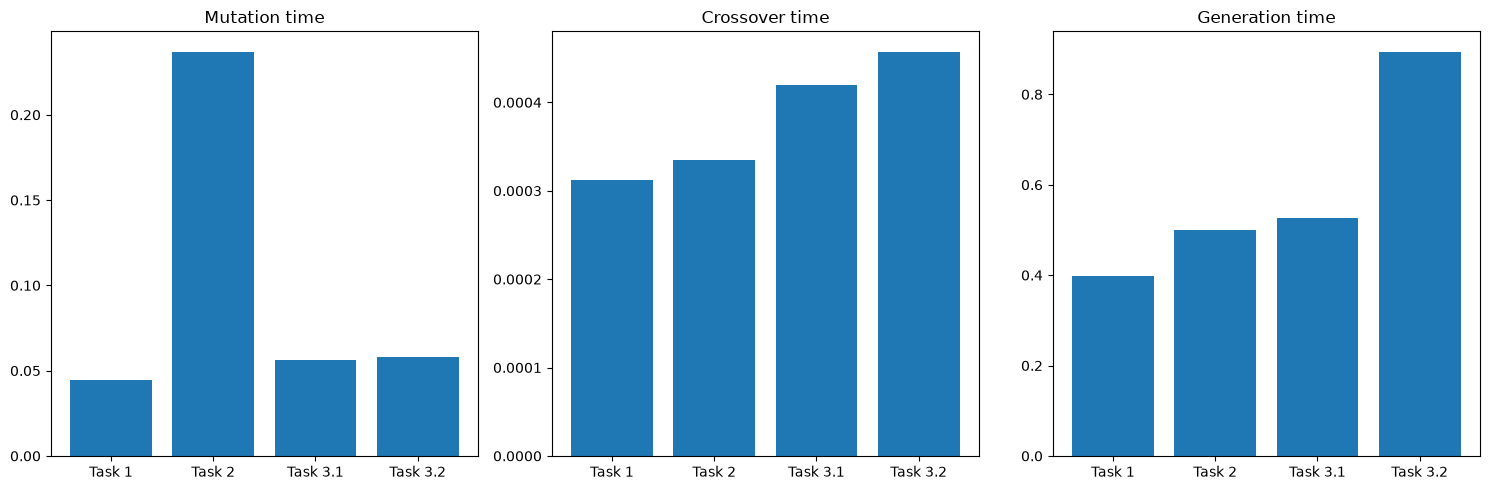

In [45]:
data = []
graph = []
data.append(task1('assets/extreme/', gen=10))
data.append(task2('assets/extreme/', gen=10))
data.append(task3('assets/extreme/', 1, gen=10))
data.append(task3('assets/extreme/', 2, gen=10))
task_names = ['Task 1', 'Task 2', 'Task 3.1', 'Task 3.2']
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.bar(task_names, [task[0] for task in data])
plt.title('Mutation time')

plt.subplot(1, 3, 2)
plt.bar(task_names, [task[1] for task in data])
plt.title('Crossover time')

plt.subplot(1, 3, 3)
plt.bar(task_names, [task[2] for task in data])
plt.title('Generation time')

plt.tight_layout()
plt.show()

### <b>Failure example</b>

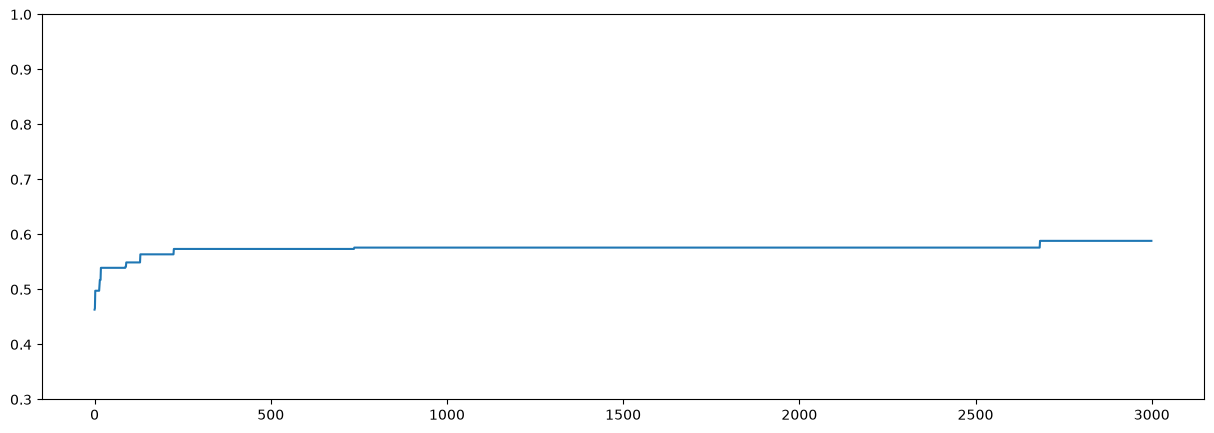

In [60]:
graph = []
task1('assets/extreme/', gen=3000)
plt.figure(figsize=(15, 5))
plt.ylim(0.3,1)
plt.plot(graph)
plt.show()